<a href="https://colab.research.google.com/github/FALAA-1285/244107020152-mobile-course/blob/main/Pertemuan%207.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## D. TUGAS PRAKTIKUM
### D1. Tugas Individu
1. Buka https://colab.research.google.com/. Setelah dipastikan bahwa google Colab terhubung dengan Github Anda, lanjutkan dengan memilih repository yang telah digunakan pada praktikum minggu lalu, rename file menjadi "Week7.ipynb". Kemudian import folder yang ada di Drive Anda.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


2. Import beberapa library berikut yang akan digunakan selama uji coba praktikum minggu ke-7 berikut.

In [25]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

3. Buat Global Threshold (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV), dengan threshold = 200, **secara manual**.


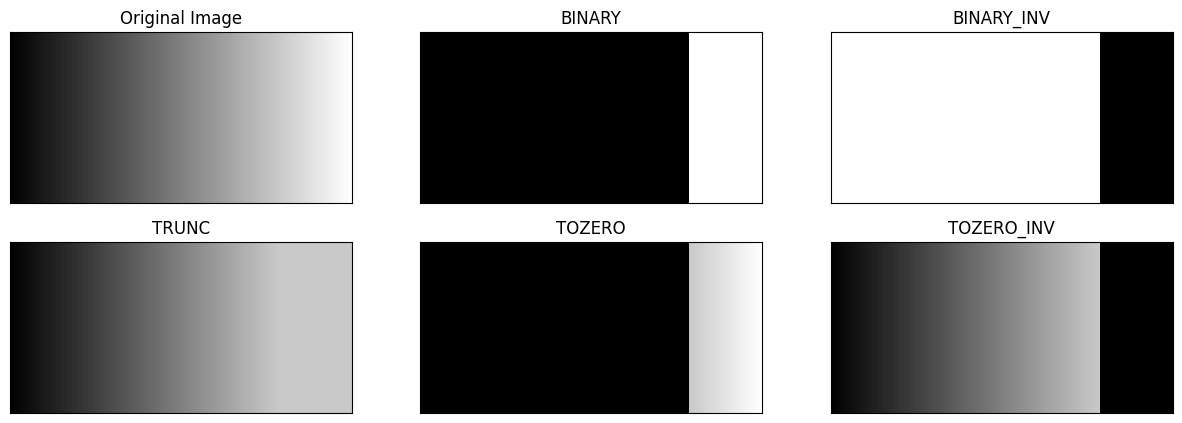

In [27]:
img = cv.imread('/content/drive/MyDrive/PCVK2026/gradient.jpg', 0)
thresh = 200
maxval = 255

#1. BINARY: pixel > thresh menjadi maxval, selain itu 0
thresh1 = np.where(img > thresh, maxval, 0)

#2. BINARY_INV: pixel > thresh menjadi 0, selain itu maxval
thresh2 = np.where(img > thresh, 0, maxval)

#3. TRUNC: pixel > thresh menjadi thresh, selain itu tetap
thresh3 = np.where(img > thresh, thresh, img)

#4. TOZERO: pixel > thresh tetap, selain itu 0
thresh4 = np.where(img > thresh, img, 0)

#5. TOZERO_INV: pixel > thresh menjadi 0, selain itu tetap
thresh5 = np.where(img > thresh, 0, img)

titles = ['Original Image','BINARY','BINARY_INV','TRUNC','TOZERO','TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize = (15,5))
for i in range(len(images)):
  plt.subplot(2,3,i+1),plt.imshow(images[i],'gray', vmin=0, vmax=255, interpolation='nearest')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

4. Buat program Adaptive Threshold: adaptive mean dan adaptive Gaussian **tanpa menggunakan cv.threshold(), cv.adaptiveThreshold(), maupun fungsi filter siap pakai** dengan menggunakan **citra Sudoku** yang memiliki pencahayaan tidak merata. Ketentuan: global threshold secara manual dengan ambang **127, ukuran jendela 11 × 11, C = 2, dan sigma = 2 untuk Gaussian**.

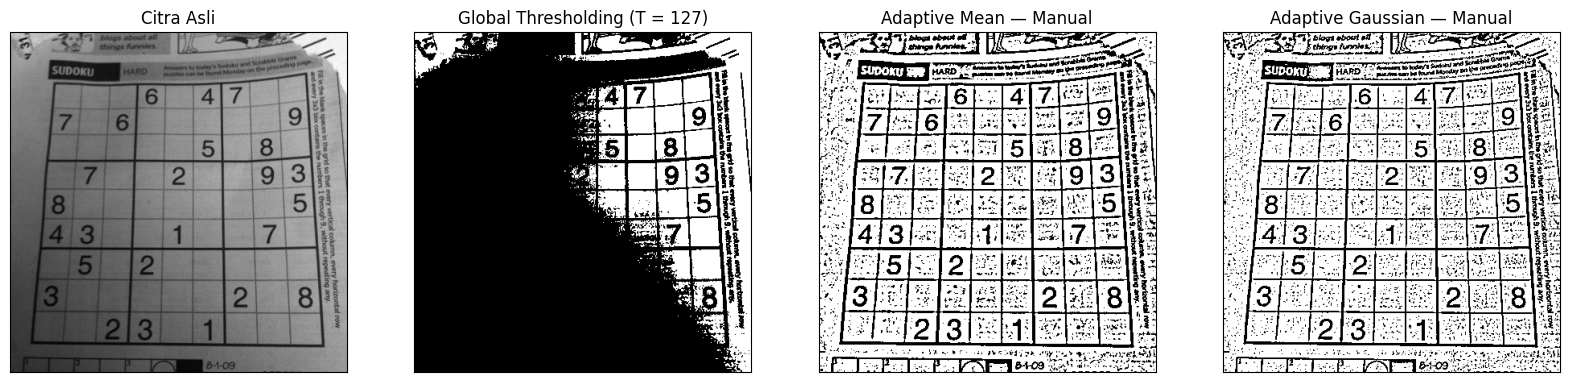

In [28]:
filename = ('/content/drive/MyDrive/PCVK2026/sudoku-original.jpg')
gray = cv.cvtColor(cv.imread(filename), cv.COLOR_BGR2GRAY)

block = 11
C = 2
sigma = 2

# Global threshold manual (ambang 127)
th1 = np.where(gray > 127, 255, 0)

# Adaptive Mean manual
def adaptive_mean(gray, block, C):
    pad = block // 2
    img = np.pad(gray.astype(np.float64), pad, mode='edge')
    hasil = np.zeros_like(gray)
    for y in range(gray.shape[0]):
        for x in range(gray.shape[1]):
            T = np.mean(img[y:y+block, x:x+block]) - C
            if gray[y, x] > T:
                hasil[y, x] = 255
    return hasil

# Adaptive Gaussian manual
def adaptive_gaussian(gray, block, C, sigma):
    ax = np.arange(block) - block // 2
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    kernel = kernel / np.sum(kernel)

    pad = block // 2
    img = np.pad(gray.astype(np.float64), pad, mode='edge')
    hasil = np.zeros_like(gray)
    for y in range(gray.shape[0]):
        for x in range(gray.shape[1]):
            T = np.sum(img[y:y+block, x:x+block] * kernel) - C
            if gray[y, x] > T:
                hasil[y, x] = 255
    return hasil

th2 = adaptive_mean(gray, block, C)
th3 = adaptive_gaussian(gray, block, C, sigma)

titles = ['Citra Asli', 'Global Thresholding (T = 127)',
          'Adaptive Mean — Manual', 'Adaptive Gaussian — Manual']
citra2 = [gray, th1, th2, th3]

plt.figure(figsize = (20,5))
for i in range(len(citra2)):
    plt.subplot(1,4,i+1),plt.imshow(citra2[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

5. A. Buat Otsu Thresholding tanpa menggunakan Library. Tampilkan juga nilai threshold saat anda gunakan Otsu's (gunakan image **lena_gs_lc2.jpg** untuk dibandingkan dengan hasil dengan penggunaan library).

/tmp/ipykernel_1445/997423736.py:19: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
/tmp/ipykernel_1445/997423736.py:20: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)


93


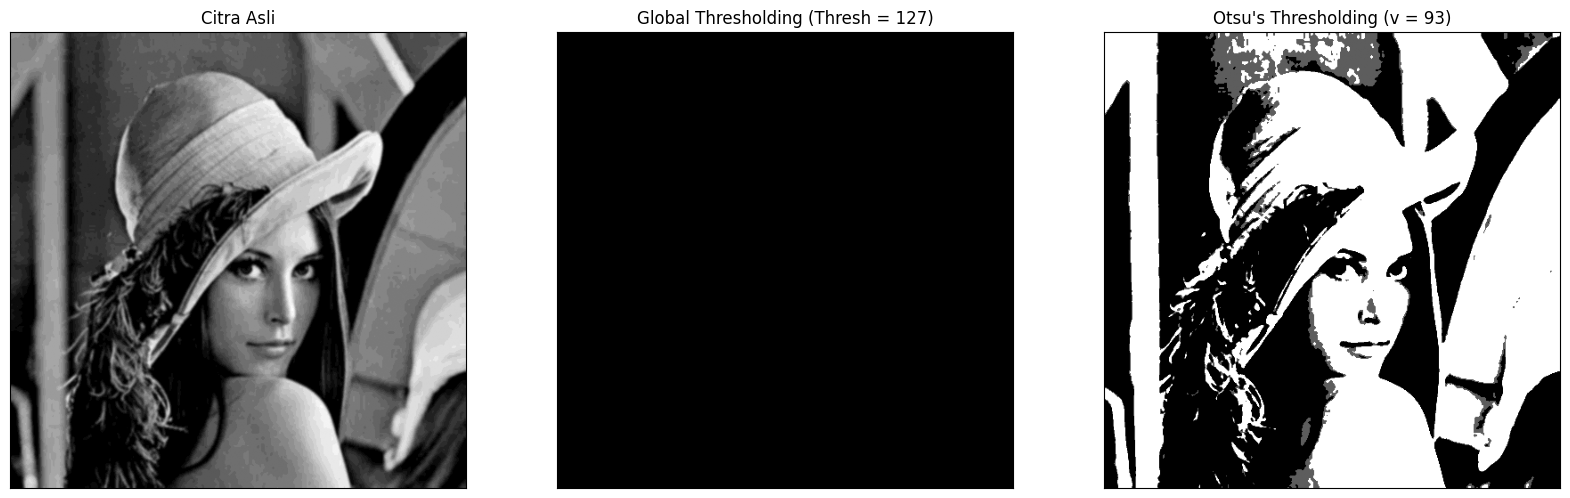

In [29]:
filename = ('/content/drive/MyDrive/PCVK2026/lena_gs_lc2.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

**Pertanyaan:** Mengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitam semua? Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas (Thresh) supaya gambar Lena ini masih terlihat?

Threshold Otsu tanpa library : 93
Threshold Otsu dengan library: 92.0
Rentang intensitas citra     : 85 - 108


/tmp/ipykernel_1445/2884140454.py:8: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(blur.ravel(),256,[0,256])


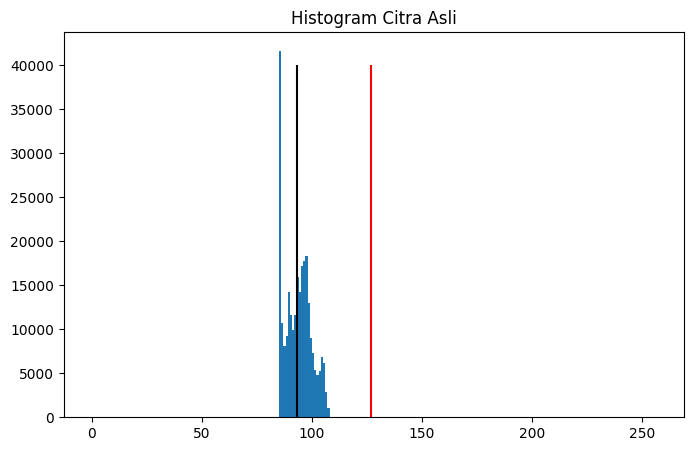

In [30]:
# Otsu dengan library sebagai pembanding
ret2,th2 = cv.threshold(blur,0,255,cv.THRESH_BINARY+cv.THRESH_OTSU)
print("Threshold Otsu tanpa library :", otsu_thresh)
print("Threshold Otsu dengan library:", ret2)
print("Rentang intensitas citra     :", blur.min(), "-", blur.max())

plt.figure(figsize = (8,5))
plt.hist(blur.ravel(),256,[0,256])
plt.vlines(thresh,0,40000,colors='red')         #garis merah: threshold global 127
plt.vlines(otsu_thresh,0,40000,colors='black')  #garis hitam: threshold otsu
plt.title('Histogram Citra Asli')
plt.show()

**Jawaban:**

Citra lena_gs_lc2.jpg adalah citra kontras rendah. Setelah di-blur, seluruh intensitas pikselnya hanya berada di rentang **85 – 108**. Pada histogram, semua piksel berkumpul di sebelah kiri garis merah (thresh = 127).

Binary Thresholding mengubah piksel yang nilainya > thresh menjadi 255 (putih) dan sisanya menjadi 0 (hitam). Karena tidak ada satu pun piksel yang nilainya lebih dari 127, seluruh piksel menjadi 0 sehingga gambar hitam semua.

Agar gambar Lena masih terlihat, nilai thresh harus berada di dalam rentang histogram, yaitu di antara **85 dan 108**. Nilai yang paling baik adalah nilai Otsu, yaitu **93** (tanpa library) atau **92** (dengan library), seperti garis hitam pada histogram.

   B. Kemudian coba dengan image **KTP** sendiri agar terlihat beda antara hasil otsu's dengan global threshold biasa.

/tmp/ipykernel_1445/997423736.py:19: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
/tmp/ipykernel_1445/997423736.py:20: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)


127


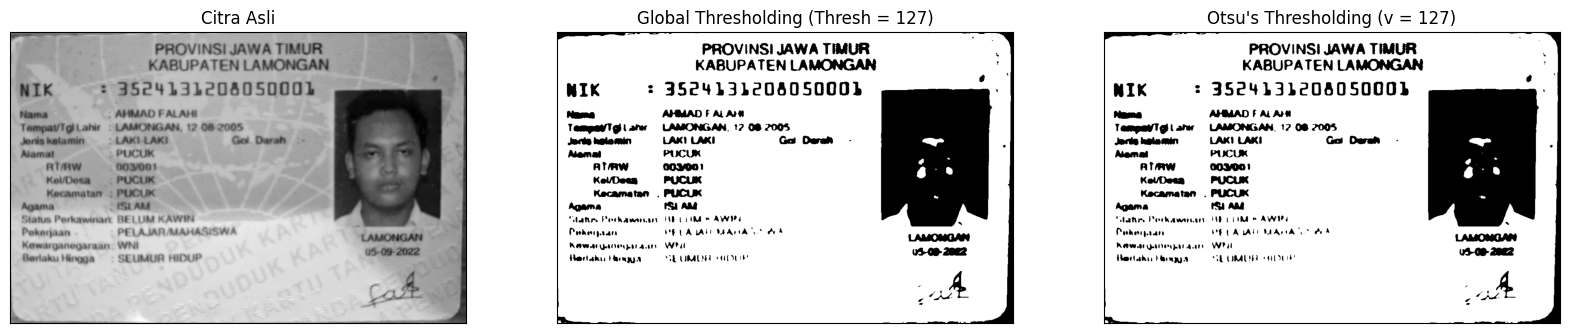

In [31]:
filename = ('/content/drive/MyDrive/PCVK2026/KTP_UTS.jpeg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

6. A. Lakukan Segmentasi Berbasis Region pada citra data.coins() dari skimage. Ketentuan:
   - Tentukan 3 seed: satu di dalam koin, satu di latar, dan satu tepat di tepi koin.
   - Jalankan dengan T = 5, 20, dan 60.
   - Tampilkan hasilnya dalam grid 3×3 (seed × T).

Seed (baris, kolom): (36, 43) | intensitas: 159
   T = 5 : 6 piksel
   T = 20 : 955 piksel
   T = 60 : 85804 piksel
Seed (baris, kolom): (88, 100) | intensitas: 88
   T = 5 : 3093 piksel
   T = 20 : 21455 piksel
   T = 60 : 81608 piksel
Seed (baris, kolom): (52, 23) | intensitas: 215
   T = 5 : 5 piksel
   T = 20 : 8 piksel
   T = 60 : 86040 piksel


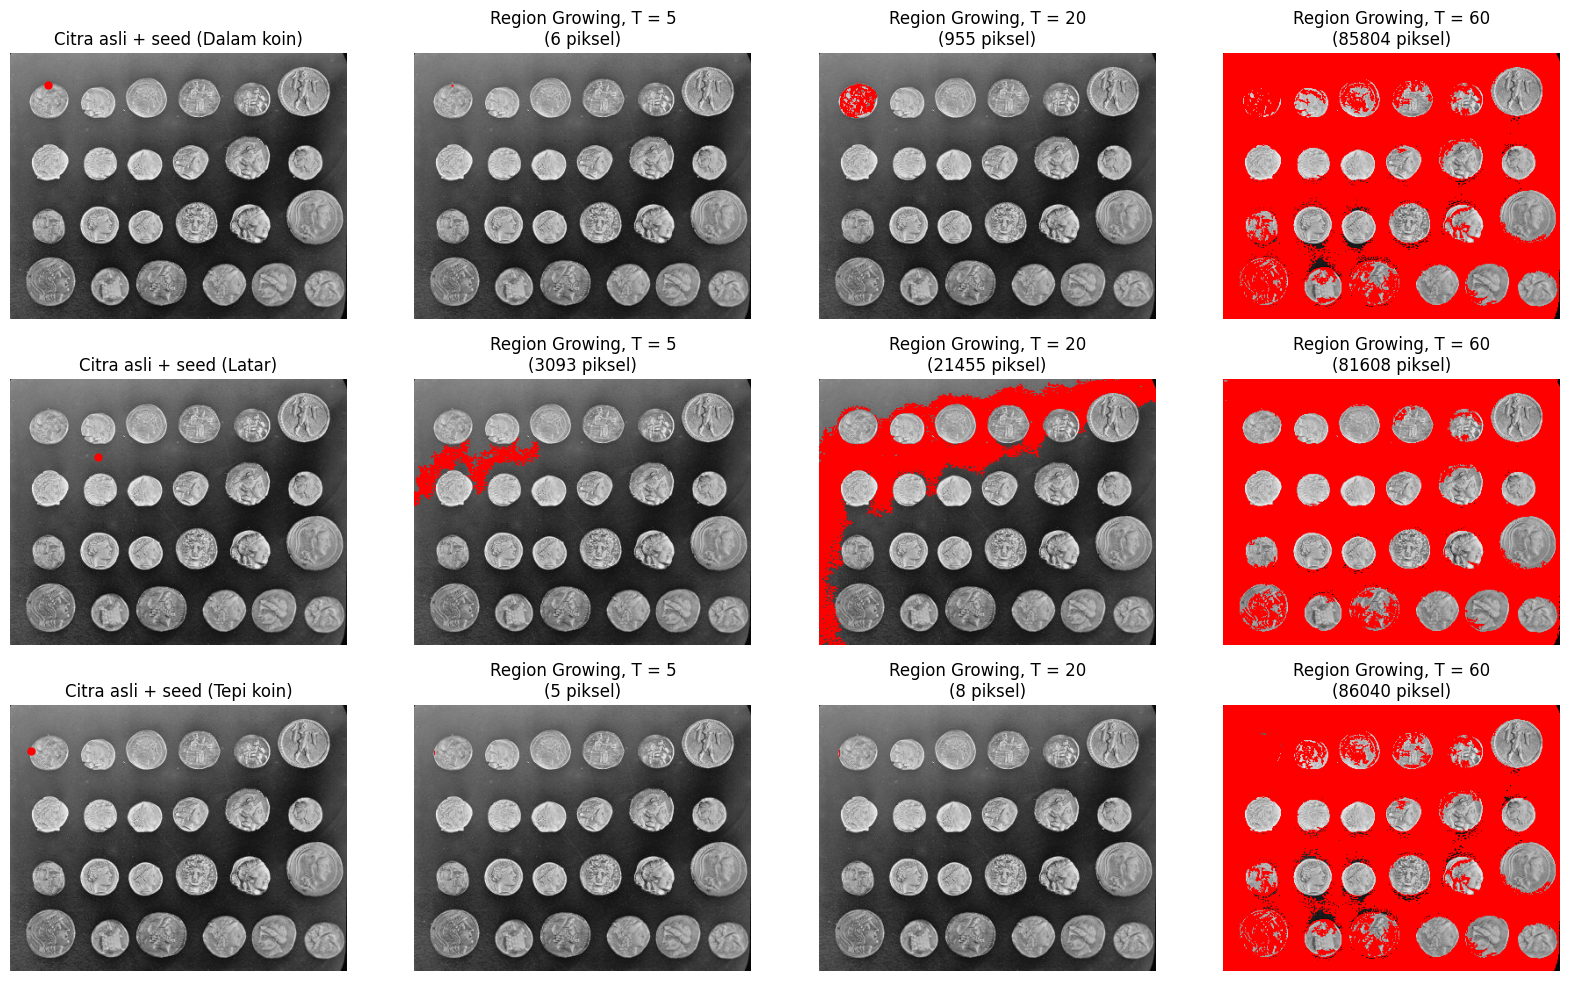

In [32]:
gray = data.coins()
seeds = [(36, 43), (88, 100), (52, 23)]       # dalam koin, latar, tepi koin
nama_seed = ['Dalam koin', 'Latar', 'Tepi koin']
daftar_T = [5, 20, 60]

def region_growing(img, seed, T):
    tinggi, lebar = img.shape
    mask = np.zeros(img.shape, dtype=bool)
    mask[seed] = True
    total = float(img[seed])
    n = 1
    antrian = deque([seed])
    while antrian:
        y, x = antrian.popleft()
        for dy, dx in [(-1, 0), (1, 0), (0, -1), (0, 1)]:      # 4 tetangga
            ny, nx = y + dy, x + dx
            if 0 <= ny < tinggi and 0 <= nx < lebar and not mask[ny, nx]:
                if abs(float(img[ny, nx]) - total / n) < T:      # |I(q) - mean region| < T
                    mask[ny, nx] = True
                    total += float(img[ny, nx])
                    n += 1
                    antrian.append((ny, nx))
    return mask

plt.figure(figsize=(20, 12))
for i, seed in enumerate(seeds):
    print('Seed (baris, kolom):', seed, '| intensitas:', gray[seed])
    plt.subplot(3, 4, i*4 + 1)
    plt.imshow(gray, 'gray')
    plt.plot(seed[1], seed[0], 'r.', markersize=10)
    plt.title('Citra asli + seed (' + nama_seed[i] + ')')
    plt.axis('off')
    for j, T in enumerate(daftar_T):
        mask = region_growing(gray, seed, T)
        hasil = color.gray2rgb(gray)
        hasil[mask] = [255, 0, 0]
        print('   T =', T, ':', np.sum(mask), 'piksel')
        plt.subplot(3, 4, i*4 + j + 2)
        plt.imshow(hasil)
        plt.title('Region Growing, T = ' + str(T) + '\n(' + str(np.sum(mask)) + ' piksel)')
        plt.axis('off')
plt.show()

   B. Gunakan **skimage.segmentation.flood()**. Fungsi ini menghasilkan mask region dari seed dengan menerima piksel yang terhubung dan intensitasnya berada dalam toleransi terhadap intensitas seed.

Seed (baris, kolom): (36, 43) | intensitas: 159
   Toleransi 5 : 21 piksel
   Toleransi 20 : 919 piksel
   Toleransi 60 : 15253 piksel
Seed (baris, kolom): (88, 100) | intensitas: 88
   Toleransi 5 : 3468 piksel
   Toleransi 20 : 21885 piksel
   Toleransi 60 : 83392 piksel
Seed (baris, kolom): (52, 23) | intensitas: 215
   Toleransi 5 : 5 piksel
   Toleransi 20 : 7 piksel
   Toleransi 60 : 1033 piksel


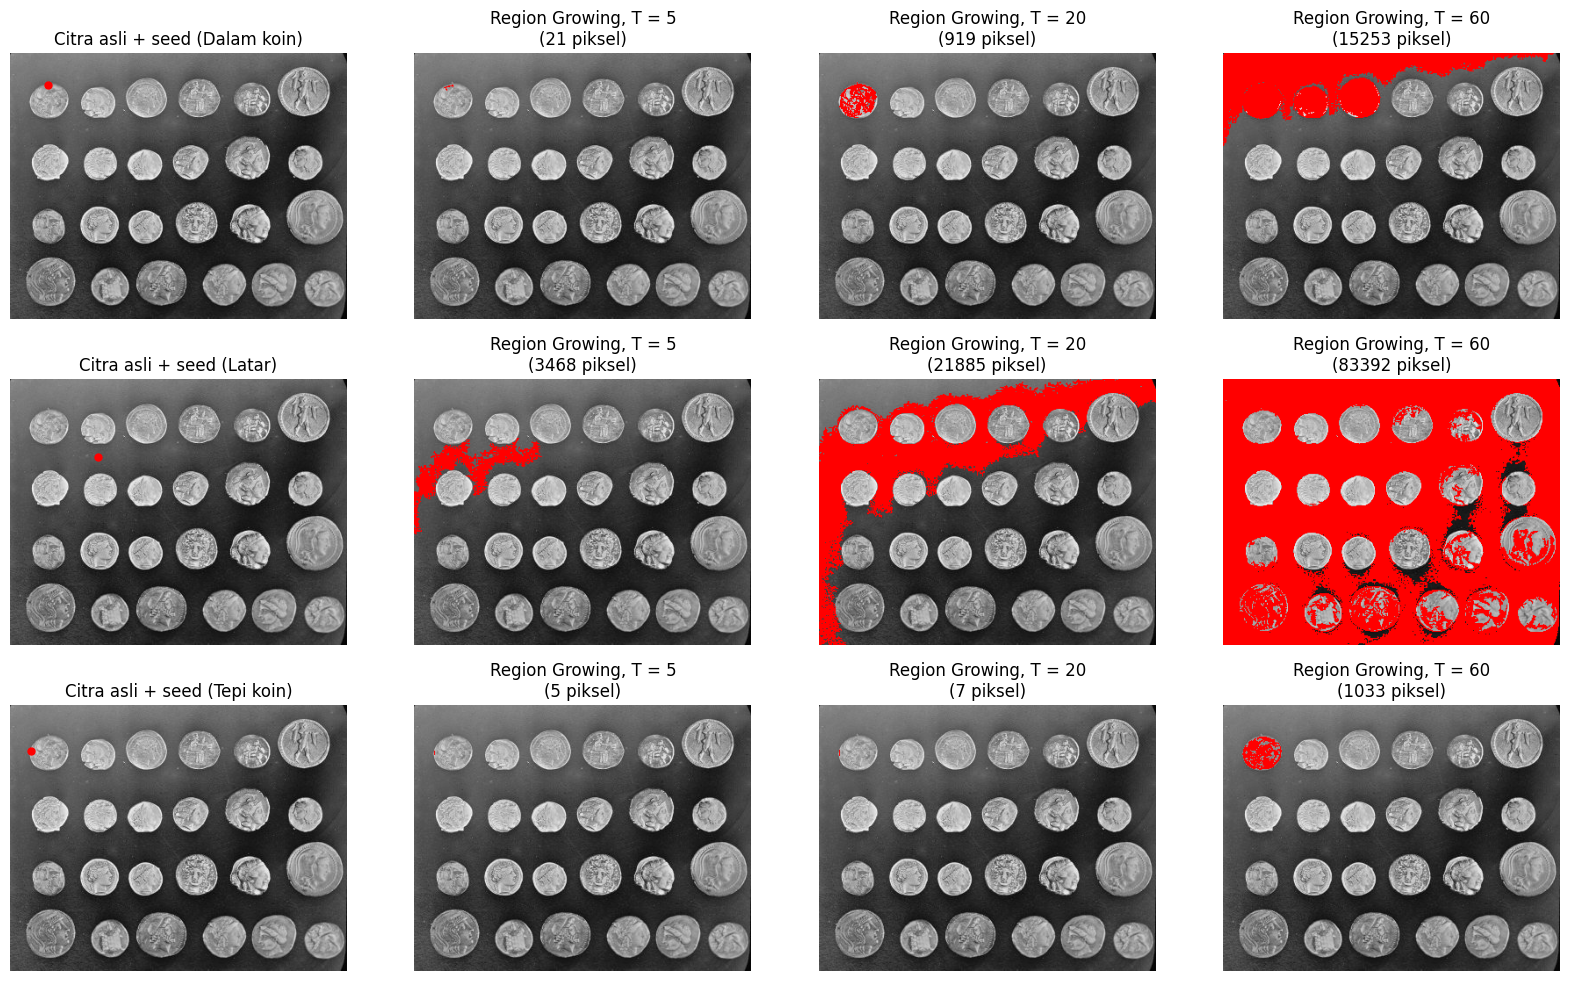

In [33]:
plt.figure(figsize=(20, 12))
for i, seed in enumerate(seeds):
    print('Seed (baris, kolom):', seed, '| intensitas:', gray[seed])
    plt.subplot(3, 4, i*4 + 1)
    plt.imshow(gray, 'gray')
    plt.plot(seed[1], seed[0], 'r.', markersize=10)
    plt.title('Citra asli + seed (' + nama_seed[i] + ')')
    plt.axis('off')
    for j, T in enumerate(daftar_T):
        # Segmentasi menggunakan fungsi siap pakai
        region = flood(
            gray,
            seed_point=seed,
            tolerance=T,
            connectivity=1       # 4 tetangga untuk citra 2D
        )
        hasil = color.gray2rgb(gray)
        hasil[region] = [255, 0, 0]
        print('   Toleransi', T, ':', np.sum(region), 'piksel')
        plt.subplot(3, 4, i*4 + j + 2)
        plt.imshow(hasil)
        plt.title('Region Growing, T = ' + str(T) + '\n(' + str(np.sum(region)) + ' piksel)')
        plt.axis('off')
plt.show()

7. Lakukan segmentasi warna pada image **ktp_fulan.jpg**, munculkan hanya warna yang **biru saja**. (Petunjuk: anda dapat gunakan K-Means untuk menampilkan hanya warna tertentu saja). Rentang mencakup biru muda kebiruan pada latar KTP (dengan warna HSV):
```
kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))
```

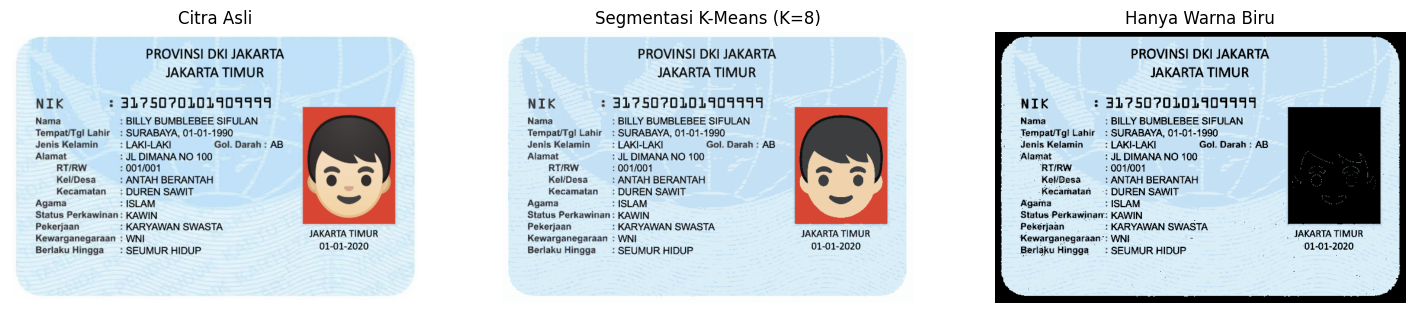

In [35]:
from sklearn.cluster import KMeans

# Baca citra dan ubah ke RGB
filename = ('/content/drive/MyDrive/PCVK2026/ktp_fulan.jpg')
img = cv.imread(filename)
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# Ubah citra menjadi array 2D (piksel)
Z = img.reshape((-1, 3))
Z = np.float32(Z)

# Tentukan jumlah cluster
k = 8
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(Z)

# Dapatkan label dan pusat cluster
labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)
# Bentuk citra hasil segmentasi
segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img.shape)

# Ambil hanya warna biru (HSV)
hsv = cv.cvtColor(segmented_img, cv.COLOR_RGB2HSV)
H, S, V = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))
hanya_biru = np.zeros_like(segmented_img)
hanya_biru[kelompok_biru] = segmented_img[kelompok_biru]

# Tampilkan hasil
plt.figure(figsize=(18,5))
plt.subplot(1,3,1)
plt.imshow(img)
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(segmented_img)
plt.title('Segmentasi K-Means (K=8)')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(hanya_biru)
plt.title('Hanya Warna Biru')
plt.axis('off')
plt.show()

### D2. Tugas Kelompok
**Proses konversi gambar KTP menjadi teks yang dapat mengenali tulisan.**

Proses konversi gambar menjadi teks dikenal dengan istilah OCR (Optical Character Recognition). Tesseract merupakan mesin OCR, sedangkan pytesseract digunakan untuk mengaksesnya melalui Python. Langkah awal adalah melakukan Instal Tesseract dan model bahasa Indonesia.

In [36]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


**Latihan: Lakukan Perbandingan Pembacaan Teks pada Citra Berwarna dan Hasil Segmentasi**

1. **Siapkan tiga citra untuk dibandingkan:** citra berwarna asli, citra hasil segmentasi menggunakan **Otsu Thresholding**, dan citra hasil segmentasi menggunakan **Adaptive Thresholding**. Gunakan ukuran citra yang sama. Untuk kedua metode thresholding, ubah citra menjadi grayscale terlebih dahulu.

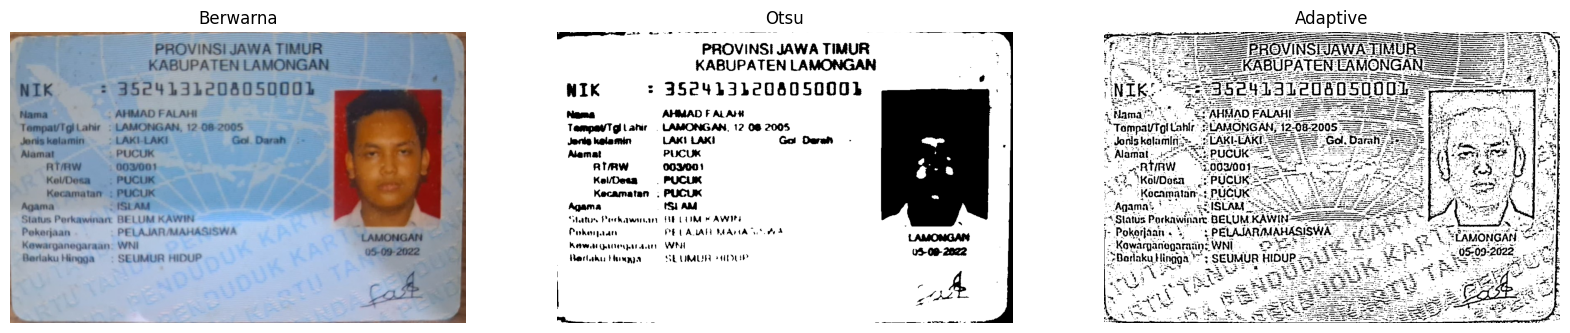

In [44]:
import pytesseract

img = cv.imread('/content/drive/MyDrive/PCVK2026/KTP_UTS.jpeg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Segmentasi Otsu Thresholding
ret, otsu_img = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

# Segmentasi Adaptive Thresholding
adaptive_img = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

judul = ['Berwarna', 'Otsu', 'Adaptive']
citra = [cv.cvtColor(img, cv.COLOR_BGR2RGB), otsu_img, adaptive_img]

plt.figure(figsize=(20, 6))
for i in range(3):
    plt.subplot(1,3,i+1),plt.imshow(citra[i],'gray')
    plt.title(judul[i])
    plt.axis('off')
plt.show()

2. **Lakukan pembacaan teks pada ketiga citra** menggunakan pytesseract.image_to_string(). Gunakan bahasa dan pengaturan --psm yang sama agar perbandingan konsisten.

In [45]:
config = '--psm 6'

for t, c in zip(judul, citra):
    print('----------', t.upper(), '----------')
    print(pytesseract.image_to_string(c, lang='ind', config=config))

---------- BERWARNA ----------
PROVINSI JAWA TIMUR
KABUPATEN LAMONGAN
4
NIK : 3504131208050001
Nama AHMAD FALAHI
Tampav/Tgi Lahir : LAMONGAN, 12 08-2005
Jenis kelamin LAKI-LAKI Gol Darah k
Namat PUCUK
ATaw 00/9001
Kel/Desa PUCUK
Kecamatar : PUCUK
Agama ISLAM
Status Perkawinan BELUM KAWIN
Bm bag Gr aa
Berlaku Hingga —: SEUMUR HIDUP 05-09-2022
9.

---------- OTSU ----------
Ba 0
PROVINSI JAWA TIMUR .
KABUPATEN LAMONGAN an
Tn)
NIK : 35041131208059901
Nama AHMAD FALAH
TampatTg lahir . LAMONGAN. 12 06 2005
Janis kelamin LAKI LAKI Ga Darah - .
Namat PUCUK
Ataw 001991
Kai/Deea . PUCUK .
Kecamatan : PUCUK
Agama ISI AM
Status Perdumwnan HELUM K AWT A
Pokaraan PELAJAR MAMA AA .
LAMONGAN
Kawat eter WN
Wentaku Hanana SEUMUR HIDUP 03-00-2022
|
| ob
Ae Da

---------- ADAPTIVE ----------
re sip KABUPATEN EAMONGANE SE
"NIK: “227 A5P4)3100A050DUL (5
(Hama, SE AHMAD PALAHI 2 5S aata belasan Ph
« Tempay/Tgl Lahir LAMONGAN, 12082005 FE... pa GR tian GO
.Jonls kolamiri.:. ..# LAKI-LAKI. 2 55 2 “Gol. Darah.

3. **Tampilkan area teks yang dikenali** menggunakan pytesseract.image_to_data() dan kotak hijau. Gunakan batas confidence yang sama, misalnya **lebih dari 60**, pada ketiga citra.

Berwarna | rata-rata confidence : 69.76
Otsu | rata-rata confidence : 54.17
Adaptive | rata-rata confidence : 20.61


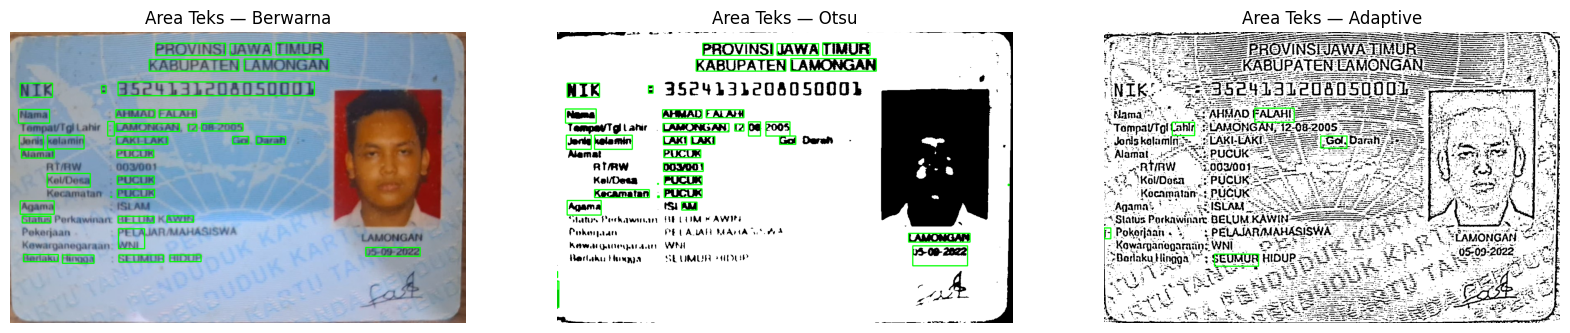

In [46]:
plt.figure(figsize=(20, 6))
for i, (t, c) in enumerate(zip(judul, citra)):
    data_ocr = pytesseract.image_to_data(c, lang='ind', config=config, output_type=pytesseract.Output.DICT)
    if len(c.shape) == 2:
        kotak = cv.cvtColor(c, cv.COLOR_GRAY2RGB)
    else:
        kotak = c.copy()

    conf = []
    for j in range(len(data_ocr['text'])):
        if data_ocr['text'][j].strip() != '' and float(data_ocr['conf'][j]) >= 0:
            conf.append(float(data_ocr['conf'][j]))
        if float(data_ocr['conf'][j]) > 60:
            x, y, w, h = data_ocr['left'][j], data_ocr['top'][j], data_ocr['width'][j], data_ocr['height'][j]
            cv.rectangle(kotak, (x, y), (x + w, y + h), (0, 255, 0), 2)

    print(t, '| rata-rata confidence :', round(np.mean(conf), 2))
    plt.subplot(1,3,i+1),plt.imshow(kotak)
    plt.title('Area Teks — ' + t)
    plt.axis('off')
plt.show()

Bandingkan hasil pembacaan dengan tulisan sebenarnya pada gambar. Pilih 10 kata atau angka yang terlihat jelas sebagai acuan, lalu isi tabel berikut. Penilaian dilakukan pada teks hasil OCR, bukan hanya pada kata yang diberi kotak.

| No. | Teks sebenarnya | OCR citra berwarna | OCR Otsu | OCR Adaptive |
|---|---|---|---|---|
| 1 | PROVINSI | PROVINSI  | PROVINSI  | (tidak terbaca)  |
| 2 | JAWA TIMUR | JAWA TIMUR | JAWA TIMUR | (tidak terbaca) |
| 3 | KABUPATEN LAMONGAN | KABUPATEN LAMONGAN | KABUPATEN LAMONGAN | KABUPATEN EAMONGANE |
| 4 | 3524131208050001 | 3504131208050001 | 35041131208059901 | (tidak terbaca) |
| 5 | AHMAD FALAHI | AHMAD FALAHI | AHMAD FALAH | AHMAD PALAHI |
| 6 | PUCUK | PUCUK | PUCUK | PUCUK |
| 7 | ISLAM | ISLAM | ISI AM | (tidak terbaca) |
| 8 | BELUM KAWIN | BELUM KAWIN | HELUM K AWT A | BELUM KAWIN |
| 9 | LAKI-LAKI | LAKI-LAKI | LAKI LAKI | LAKI-LAKI |
| 10 | SEUMUR HIDUP | SEUMUR HIDUP | SEUMUR HIDUP | SEUMUR BOUp |

Hitung persentase kecocokan untuk setiap metode. Hasil dinyatakan cocok jika seluruh huruf atau angka pada item sama dengan acuan; abaikan perbedaan huruf besar dan kecil serta spasi di awal/akhir. Item yang tidak terbaca dihitung sebagai tidak cocok.

Kecocokan = (Jumlah item yang terbaca tepat / 10) × 100%

| Citra masukan OCR | Item terbaca tepat | Kecocokan (%) | Rata-rata confidence |
|---|---|---|---|
| Berwarna asli | 9 | 90% | 69,76 |
| Segmentasi Otsu | 5 | 50% | 54,17 |
| Segmentasi Adaptive | 3 | 30% | 20,61 |

Pertanyaan analisis:

1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel.
2. Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks tidak terbaca.
3. Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil percobaan.
4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?
5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?

Jawaban:

1. Citra berwarna asli menghasilkan pembacaan paling tepat. 9 dari 10 item terbaca benar (kecocokan 90%), sedangkan citra Otsu hanya 5 item (50%) dan citra Adaptive hanya 3 item (30%).
2. Contoh kesalahan pembacaan: pada citra berwarna, NIK 3524131208050001 terbaca "3504131208050001" (angka 2 terbaca 0). Pada citra Otsu, NIK terbaca "35041131208059901" (angka salah dan bertambah), AHMAD FALAHI terbaca "AHMAD FALAH" (huruf hilang), dan ISLAM terbaca "ISI AM". Pada citra Adaptive, KABUPATEN LAMONGAN terbaca "KABUPATEN EAMONGANE" dan NIK tidak terbaca.
3. Tidak. Pada percobaan ini segmentasi justru menurunkan ketepatan: Otsu turun dari 90% menjadi 50% dan Adaptive menjadi 30%. Citra KTP sudah cukup kontras sehingga langsung terbaca dengan baik, sedangkan thresholding membuat huruf putus/menyatu dan menghasilkan banyak noise.
4. Latar KTP berpola halus (watermark) dengan gradasi warna. Pada Otsu, satu ambang untuk seluruh citra membuat sebagian huruf dan pola latar menyatu sehingga huruf rusak. Pada Adaptive dengan jendela 11 × 11, pola latar diperjelas menjadi banyak bintik dan garis hitam yang dianggap sebagai teks, sehingga hasil OCR berisi teks acak.
5. Ya. Citra berwarna memiliki rata-rata confidence tertinggi (69,76) sekaligus kecocokan tertinggi (90%). Urutan confidence (69,76 > 54,17 > 20,61) sama dengan urutan kecocokan (90% > 50% > 30%).